<font color = LightBlue Size  = 10>Fatemeh Mohammadi  
 SID: 810199489  
 HW1</font>

# <font color = lightGreen> Problem 1: 
 Food Recommendation System  </font>

## <font> Setup </font>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random
from scipy.stats import beta

In [2]:
SID = 810199489

num_arms = ((SID) % 100) % 5 + 2
probabilities = [int(digit)/10 for digit in str(SID)[-num_arms:]]

print(f"Num arms: {num_arms}")
print(f"Probabilities: {probabilities}")

Num arms: 6
Probabilities: [0.1, 0.9, 0.9, 0.4, 0.8, 0.9]


## <font> Simulation Function </font>

In [3]:
num_rounds = 50000

In [4]:
def simulate(algorithm, probabilities, num_rounds):
    rewards = np.zeros(num_rounds)
    regrets = np.zeros(num_rounds)
    max_expected_reward = np.max(probabilities)

    for round_i in range(num_rounds):
        arm = algorithm.select_arm()
        reward = 1 if random.random() < probabilities[arm] else 0
        algorithm.update(arm, reward)

        rewards[round_i] = reward
        regrets[round_i] =  max_expected_reward - probabilities[arm]

    return rewards, regrets

## <font>Thompson Sampling Algorithm </font>

In [5]:

class thompson_sampling:
    def __init__(self, num_arms):
        self.num_arms = num_arms
        self.alpha = np.ones(num_arms)
        self.beta = np.ones(num_arms)

    def select_arm(self):
        samples = [beta.rvs(self.alpha[i], self.beta[i]) for i in range(self.num_arms)]
        return np.argmax(samples)

    def update(self, arm, reward):
        self.alpha[arm] += reward
        self.beta[arm] += (1 - reward)

## <font> Upper Confidence Bound (UCB) Algorithm </font>

The Key Idea of UCB:

For each arm, UCB calculates a score based on the formula:

$
\text{UCB}(a) = \hat{\mu}_a + c \times \sqrt{\frac{\ln t}{N_a}}
$

Where:
- $ \hat{\mu}_a $: The average reward obtained from arm $ a $ so far (this is the **exploitation** term).
- $ c $: A constant that controls the amount of exploration.
- $ t $: The current time step (or number of rounds played).
- $ N_a $: The number of times arm $ a $ has been played so far (this affects **exploration**).

The **confidence interval** $ \sqrt{\frac{\ln t}{N_a}} $ shrinks as you play an arm more frequently, meaning the algorithm becomes more confident about its average reward. Arms that have been tried less often will have larger confidence intervals, giving them a chance to be explored.



In [6]:
UCB_C = 1

class UCB:
    def __init__(self, num_arms, c = UCB_C):
        self.num_arms = num_arms
        self.c = c
        self.t = 0
        self.counts = np.zeros(num_arms)
        self.means = np.zeros(num_arms)
        self.UCBs = [float('inf') for _ in range(num_arms)]

    def select_arm(self):
        # print(self.UCBs)
        if self.t < self.num_arms:
            return self.t
        else:
            return np.argmax(self.UCBs)

    def update(self, arm, reward):
        self.t += 1

        self.counts[arm] += 1
        self.means[arm] += (reward - self.means[arm]) / self.counts[arm]
        self.UCBs[arm] = self.means[arm] + self.c * np.sqrt(np.log(self.t) / self.counts[arm])

## <font> Epsilon-Greedy Algorithm </font>

epsilon ? ro befhamim ya motaghaier?

In [7]:
class epsilon_greedy:
    def __init__(self, num_arms, initial_epsilon=1.0, min_epsilon=0.01, decay_rate=0.99):
        self.num_arms = num_arms
        self.min_epsilon = min_epsilon
        self.epsilon = initial_epsilon
        self.decay_rate = decay_rate
        self.counts = np.zeros(num_arms)
        self.means = np.zeros(num_arms)
        self.q_values = np.zeros(num_arms)

    def select_arm(self):
        if random.random() < self.epsilon:
            return  random.randint(0, self.num_arms - 1)
        else:
            return  np.argmax(self.q_values)

    def update(self, arm, reward):
        self.counts[arm] += 1
        self.means[arm] += (reward - self.means[arm]) / self.counts[arm]

        alpha = 1 / (self.counts[arm])
        self.q_values[arm] += (alpha) * (reward - self.q_values[arm])
        self.epsilon = max(self.min_epsilon, self.epsilon * self.decay_rate)


## <font> Simulation </font>


In [8]:
rewards_ts, regrets_ts = simulate(thompson_sampling(num_arms), probabilities, num_rounds)
cumulative_reward_ts = np.cumsum(rewards_ts)
cumulative_regret_ts = np.cumsum(regrets_ts)

In [9]:
rewards_ucb, regrets_ucb = simulate(UCB(num_arms), probabilities, num_rounds)
cumulative_reward_ucb = np.cumsum(rewards_ucb)
cumulative_regret_ucb = np.cumsum(regrets_ucb)

In [10]:
rewards_eg, regrets_eg = simulate(epsilon_greedy(num_arms), probabilities, num_rounds)
cumulative_reward_eg = np.cumsum(rewards_eg)
cumulative_regret_eg = np.cumsum(regrets_eg)

## <font> Analysis </font>


In [11]:
def plot_results(ts, ucb, eg, title):
    plt.figure(figsize=(5, 5))

    plt.plot(ts, label="Thompson Sampling")
    plt.plot(ucb, label="UCB")
    plt.plot(eg, label="Epsilon Greedy")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


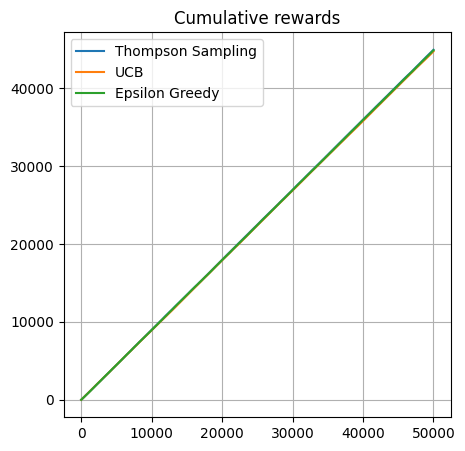

In [12]:
plot_results(cumulative_reward_ts, cumulative_reward_ucb, cumulative_reward_eg, "Cumulative rewards")

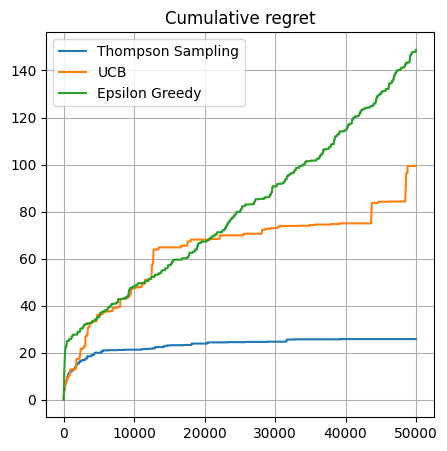

In [13]:
plot_results(cumulative_regret_ts, cumulative_regret_ucb, cumulative_regret_eg, "Cumulative regret")

## <font> Parameter analysis setup </font>


In [14]:
ucb_exploration_factors = [0.1, 0.5, 1, 2]
epsilon_greedy_epsilons = [0.1, 0.5, 1]

# <font color = lightGreen> Problem 2: 
Advertising in an Online Store  </font>

We assume that the reward is observed only after every two rounds, and then the process resets. For example, the sequence might look like: 0 (no), 1 (yes), 2 (no), ... We do not encounter situations like 0 (no), 1 (yes), 2 (yes), 3 (yes) ...( because there is always an ad shown prior to time steps 1, 2, and so on.)

In [27]:
def show_ad(ad):
    print(f"Ad: {ad}")

def observe_reward():
    # get 1 or 0 from user
    return np.random.randint(2)


In [42]:

def Approach1_epsilon_greedy_mdp(user_is_active, initial_epsilon=1.0, min_epsilon=0.01, decay_rate=0.99):
    ad1 = 0
    ad2 = 1
    q_value = [[0, 0], [0, 0]]  # q_values[state][action] -> rewards for transitions from state 0 or 1 with action 0 (Ad 1) or 1 (Ad 2)
    counts = [[0, 0], [0, 0]]  # counts[state][action] -> number of times each state-action pair was chosen
    state = np.random.choice([ad1, ad2])  # Initial state (randomly choose to start with Ad 1 or Ad 2)

    epsilon = initial_epsilon

    t = 0
    while(user_is_active):
        if t % 2 == 0:  # Even step: choose the first ad (no reward yet)
            if np.random.rand() < epsilon:  # Exploration
                action = np.random.choice([ad1, ad2])
            else:  # Exploitation
                action = np.argmax(q_value[state])


            show_ad(action)
            ### there no reward so we don't update
            # reward = observe_reward()
            # counts[state][action] += 1
            # alpha = 1 / (N[state][action])
            # q_value[state][action] += alpha * (reward - q_value[state][action])
            ###
            state = action



        else:  # Odd time step, show the second ad + observe the reward
            if np.random.rand() < epsilon:  # Exploration
                action = np.random.choice([ad1, ad2])
            else:  # Exploitation
                action = np.argmax(q_value[state])


            show_ad(action)
            counts[state][action] += 1
            reward = observe_reward()
            alpha = 1 / (counts[state][action])
            q_value[state][action] += alpha * (reward - q_value[state][action])

            state = action

        t += 1

        epsilon = max(min_epsilon, epsilon * decay_rate)

In [43]:
def Approach2_epsilon_greedy(user_is_active, initial_epsilon=1.0, min_epsilon=0.01, decay_rate=0.99):
    ad1 = 0
    ad2 = 1
    q_values = np.zeros(4) #Save estimated rewards for [(Ad1 -> Ad2), (Ad2 -> Ad1), (Ad1 -> Ad1), (Ad2 -> Ad2)] in q_values
    counts = np.zeros(4) # Number of trials for each sequence in counts
    sequences = [[ad1, ad2], [ad2, ad1], [ad1, ad1], [ad2, ad2]] # List of possible sequences (Actions)
    current_sequence = None
    action = None

    epsilon = initial_epsilon

    t = 0
    while(user_is_active):
        if t % 2 == 0:  # Even time step, choose a sequence  (no reward yet)
            if np.random.rand() < epsilon:  # Exploration
                action = np.random_choice([0, 1, 2, 3])
            else:  # Exploitation
                action = np.argmax(q_values)

            current_sequence = sequences[action]  # Get the chosen sequence (first and second ad)
            first_ad = current_sequence[0]  # First ad in the sequence

            show_ad(first_ad)

        else:  # Odd time step, show the second ad + observe the reward
            second_ad = current_sequence[1]
            show_ad(second_ad)

            # Observe the reward after showing the second ad
            Reward = observe_reward()

            counts[action] += 1
            alpha = 1 / counts[action]
            q_values[action] += (Reward - q_values[action]) * alpha

        t += 1

        epsilon = max(min_epsilon, epsilon * decay_rate)

In [39]:
def user_is_active():
    pass


In [40]:
def run(num_users, epsilon, approach):
    for user in range(num_users):
        if approach == 1:
            Approach1_epsilon_greedy_mdp(epsilon, user_is_active())
        elif approach == 2:
            Approach2_epsilon_greedy(epsilon, user_is_active())
        else:
            print("Invalid approach selected. Please choose 1 or 2.")

# <font color = lightGreen> Problem 3: 
Social Mobile  </font>